# Jacobian of the matter power spectrum

How the matter power spectrum $P(k, a)$ responds to each parameter, across scale and time. One `jax.jacfwd` gives the Jacobian with respect to ten parameters of $w_0 w_a$CDM with a massive neutrino.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from discoeb import W0WACDM_MNU, solve_eb

K = np.geomspace(1.0e-4, 1.0, 64)  # wave numbers, 1/Mpc
A_OUT = np.geomspace(0.01, 1.0, 48)  # scale factors of the map

## The model and its parameters

`W0WACDM_MNU` has a dark-energy fluid with $w(a) = w_0 + w_a (1 - a)$ and one massive neutrino. `FIDUCIAL` gives the cosmology in $\Omega_m$, $\Omega_b$ and $H_0$, which `from_density_parameters` converts into the model's physical densities. `PARAMETERS` names the ten keys to differentiate and their plot labels.

In [2]:
FIDUCIAL = dict(
    Omega_m=0.3099,
    Omega_b=0.0488911,
    H_0=67.742,
    A_s=2.1064e-9,
    n_s=0.96822,
    T_cmb=2.7255,
    Y_He=0.248,
    N_eff=2.046,  # the massless flavours
    N_mnu=1,
    m_nu=0.06,  # eV
    w_DE_0=-0.99,
    w_DE_a=0.0,
    cs2_DE=1.0,
)
PARAMETERS = {  # key: label
    "H_0": "H_0",
    "Omega_m": r"\Omega_m",
    "Omega_b": r"\Omega_b",
    "N_eff": r"N_\mathrm{eff}",
    "m_nu": r"m_\nu",
    "T_cmb": r"T_\mathrm{CMB}",
    "A_s": "A_s",
    "n_s": "n_s",
    "w_DE_0": "w_0",
    "w_DE_a": "w_a",
}
theta = jnp.asarray([FIDUCIAL[key] for key in PARAMETERS])

## Save points

`solve_eb` integrates in the scale factor, records at the scale factors you pass it, and differentiates at fixed scale factor. So the map's scale factors are the save points, and each derivative is taken at fixed redshift.

In [3]:
# The solve saves at the map's scale factors themselves.
print(f"{len(A_OUT)} scale factors from z = {1 / A_OUT[0] - 1:.0f} to today")

48 scale factors from z = 99 to today


## From the parameters to $P(k, a)$

Both contrasts are per unit primordial curvature, so the spectrum of the cold dark matter and the baryons together is

$$
P(k, a) = \frac{2 \pi^2}{k^3} A_s \left(\frac{k}{k_p}\right)^{n_s - 1} \delta(k, a)^2,
\qquad
\delta = \frac{\omega_c\, \delta_c + \omega_b\, \delta_b}{\omega_c + \omega_b} .
$$

In [4]:
def power(theta):
    """``P(k, a)`` of CDM and baryons in Mpc^3, ``(len(K), len(A_OUT))``."""

    cosmology = W0WACDM_MNU.from_density_parameters(
        **{**FIDUCIAL, **dict(zip(PARAMETERS, theta))}
    )
    values = solve_eb(cosmology, K, A_OUT, keep=("delta_c", "delta_b"))
    delta_c, delta_b = values[0]  # each (k, a)
    omega_c, omega_b = cosmology.omega_c, cosmology.omega_b
    delta = (omega_c * delta_c + omega_b * delta_b) / (omega_c + omega_b)
    k = K[:, None]
    primordial = cosmology.A_s * (k / cosmology.k_p) ** (cosmology.n_s - 1.0)
    return 2.0 * jnp.pi**2 / k**3 * primordial * delta**2

## The Jacobian

The eight parameters that enter the Einstein-Boltzmann solve share one forward-sensitivity launch. $A_s$ and $n_s$ enter only the primordial spectrum, so they cost nothing.

The response is $\partial \ln P / \partial \ln p$, or $\partial \ln P / \partial p$ for $w_a$, whose fiducial value is zero.

In [5]:
pk = power(theta)
jacobian = jax.jacfwd(power)(theta)  # (k, a, parameter)
# d ln P / d ln p, or d ln P / d p for a parameter whose fiducial value is zero
scale = jnp.where(theta == 0.0, 1.0, theta)
response = np.asarray(scale * jacobian / pk[..., None])

## The response today

In [6]:
print("d ln P(k) / d ln p today (d ln P / d p for w_DE_a)")
print(f"{'k [1/Mpc]':>10}" + "".join(f"{key:>9}" for key in PARAMETERS))
for i in range(0, len(K), 9):
    print(f"{K[i]:10.3e}" + "".join(f"{v:9.3f}" for v in response[i, -1]))

d ln P(k) / d ln p today (d ln P / d p for w_DE_a)
 k [1/Mpc]       H_0   Omega_m   Omega_b     N_eff      m_nu     T_cmb      A_s      n_s   w_DE_0   w_DE_a
 1.000e-04   -3.982   -1.528    0.000   -0.000   -0.007   -0.027    1.000   -6.017    0.233   -0.052
 3.728e-04   -3.960   -1.516    0.000   -0.002   -0.007   -0.046    1.000   -4.743    0.288   -0.075
 1.389e-03   -3.799   -1.435    0.000   -0.014   -0.005   -0.208    1.000   -3.469    0.459   -0.141
 5.179e-03   -3.111   -1.087   -0.003   -0.068   -0.009   -0.903    1.000   -2.195    0.504   -0.157
 1.931e-02   -1.108    0.075   -0.164   -0.172   -0.019   -2.422    1.000   -0.921    0.507   -0.159
 7.197e-02    0.510    1.370   -0.651   -0.310   -0.024   -4.396    1.000    0.353    0.507   -0.159
 2.683e-01    1.764    2.051   -0.705   -0.356   -0.025   -5.444    1.000    1.627    0.507   -0.159
 1.000e+00    2.403    2.456   -0.789   -0.382   -0.025   -6.107    1.000    2.901    0.507   -0.159


## The response across scale and time

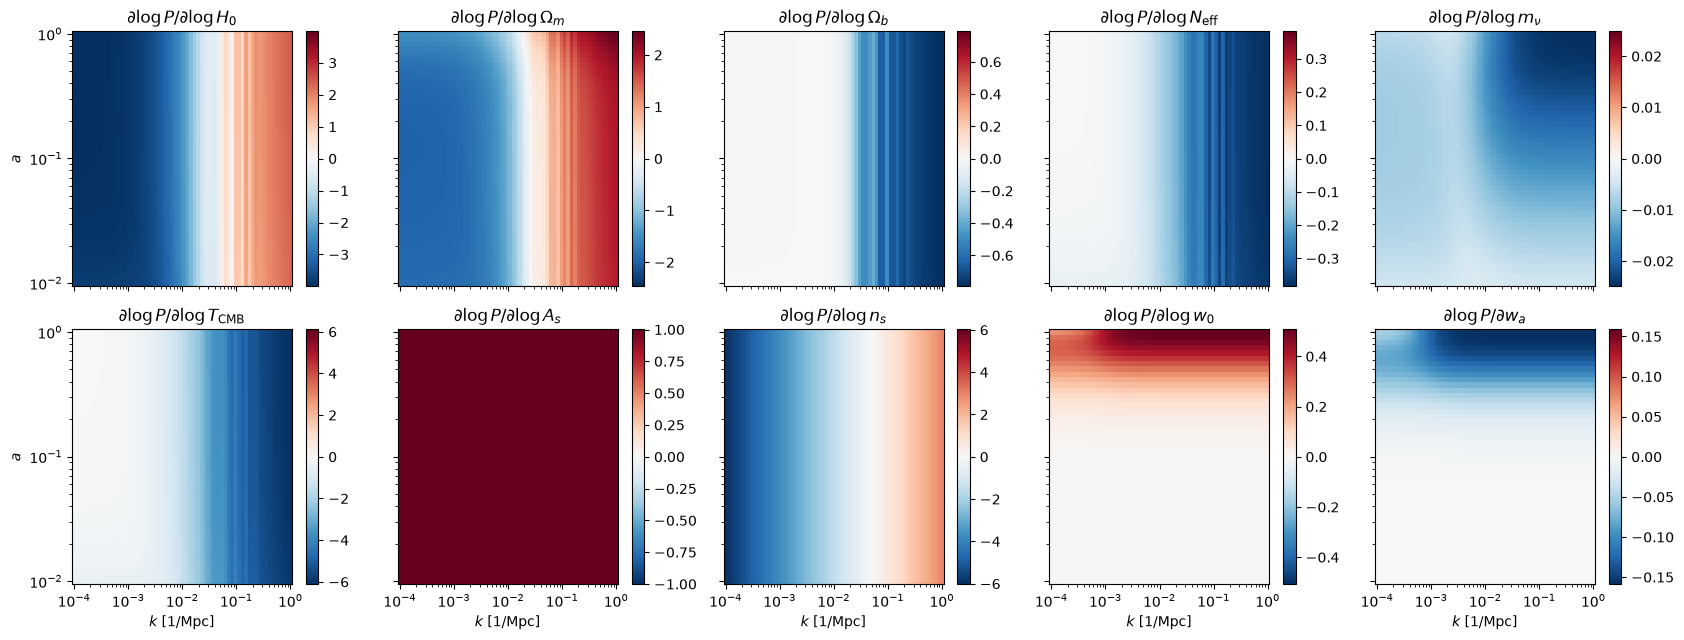

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6.5), sharex=True, sharey=True)
for i, (ax, label) in enumerate(zip(axes.flat, PARAMETERS.values())):
    limit = np.abs(response[..., i]).max()
    mesh = ax.pcolormesh(
        K, A_OUT, response[..., i].T, cmap="RdBu_r", vmin=-limit, vmax=limit
    )
    fig.colorbar(mesh, ax=ax)
    log = "" if theta[i] == 0.0 else r"\log "
    ax.set_title(rf"$\partial \log P / \partial {log}{label}$")
    ax.loglog()
for ax in axes[-1]:
    ax.set_xlabel(r"$k$ [1/Mpc]")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$a$")
fig.tight_layout()
plt.show()